In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [3]:
img = cv2.imread("sample_image.jpg", cv2.IMREAD_GRAYSCALE)

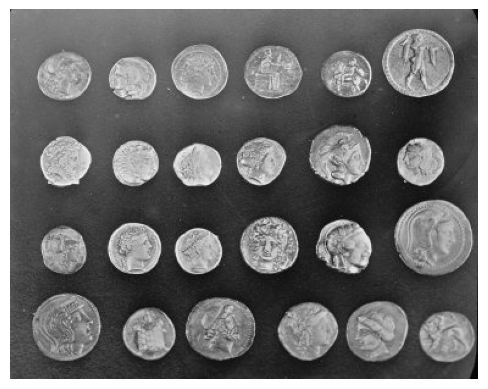

In [5]:
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

In [9]:
demo_kernel = np.array([[1, 2, 1],
               [2, 4, 2],
               [1, 2, 1]], dtype=np.float32) / 16.0

In [10]:
test_row, test_col = 150, 150

In [12]:
# correlation at this one pixel: multiply the kernel directly over the image patch (no flipping) and sum.
patch = img[test_row - 1: test_row + 2, test_col - 1: test_col + 2]
correlation_at_pixel = np.sum(patch * demo_kernel)

In [14]:
# convolution at this one pixel: flip thekernel 180 degrees first, then multiply and sum.
flipped_kernel = np.flip(demo_kernel)
convolution_at_pixel = np.sum(patch * flipped_kernel)

In [15]:
print(f"at pixel ({test_row}, {test_col}):")
#print("manual correlation result:", corre

at pixel (150, 150):


In [ ]:
# use a non sysmmetric kernel to show correlation and convolution differ

In [16]:
asymmetric_kernel = np.sum([[1, 2, 3],
                            [0, 0, 0],
                            [-1, -2, -3]], dtype=np.float32)

In [23]:
correlation_asym = np.sum(patch * asymmetric_kernel)
convolution_asym = np.sum(patch * np.flip(asymmetric_kernel))

In [25]:
print("\nwith a non-symmetric kernel:")
print("correlation result:", correlation_asym)
print("convolution result:", convolution_asym)
print("(These differ because convolution flips the kernel first.)")


with a non-symmetric kernel:
correlation result: 0.0
convolution result: 0.0
(These differ because convolution flips the kernel first.)


In [26]:
# apply the kernel across who9 whole image using opencv s built in cv2.filter2D function.
# cv2.filter2D performs correlation (it does not flip the kernel for us)
correlated_full_cv2 = cv2.filter2D(img, -1, demo_kernel)

In [27]:
flipped_demo_kernel = np.flip(demo_kernel)
convolved_full_cv2 = cv2.filter2D(img, -1, flipped_demo_kernel)

(np.float64(-0.5), np.float64(383.5), np.float64(302.5), np.float64(-0.5))

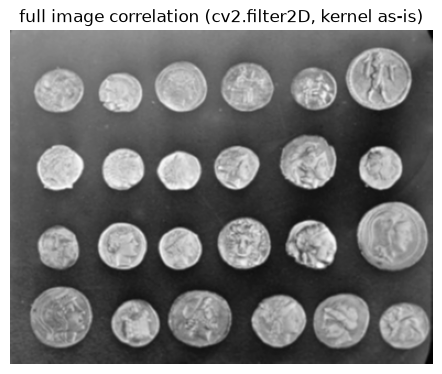

In [28]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(correlated_full_cv2, cmap="gray")
plt.title("full image correlation (cv2.filter2D, kernel as-is)")
plt.axis("off")

In [29]:
# effect of kernel size on smoothing stength
kernel_3 = np.ones((3, 3), dtype=np.float32) / 9
kernel_7 = np.ones((7, 7), dtype=np.float32) / 49
kernel_15 = np.ones((15, 15), dtype=np.float32) / 225

In [30]:
result_3 = cv2.filter2D(img, -1, kernel_3)
result_7 = cv2.filter2D(img, -1, kernel_7)
reslt_15 = cv2.filter2D(img, -1, kernel_15)

In [ ]:
plt.figure(figsize=(16, 4))